# Laboratório do Detector de Overfitting

*Material complementar de* **Mastering CatBoost — Pro Edition**, Capítulo 4: Ajuste & Diagnósticos como Controle de Sistema, §4.4 (O Piloto Automático: OD como Sistema de Segurança).

Adivinhar o número "certo" de árvores raramente é possível antes do treinamento, pois a contagem ótima depende da taxa de aprendizado e do nível de ruído dos dados. A resposta do CatBoost é a estratégia de *Iteration Overcommit*: solicitar muito mais árvores do que o necessário, monitorar uma métrica de validação e deixar o Detector de Overfitting abortar. Este laboratório executa os dois modos do detector (`Iter` e `IncToDec`) em dados deliberadamente ruidosos, expõe ambos os modos de falha (parada prematura e nunca parar) e verifica exatamente o que `use_best_model` faz com o modelo final.

In [1]:
%pip install -q catboost==1.2.10 scikit-learn==1.6.1 numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0

import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier, Pool

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

/mnt/vms/PROJETOS_DATA_SCIENCE/catboost/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


## 1. Um conjunto de dados projetado para sofrer overfitting

Ruído nos rótulos (`flip_y=0.25`) combinado a um tamanho de amostra modesto oferece ao modelo bastante ruído para memorizar — a perda de validação realmente sofrerá inflexão para cima, garantindo que o detector tenha algo real para detectar.

In [2]:
from sklearn.datasets import make_classification
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=6_000, n_features=20, n_informative=8,
                           n_redundant=4, flip_y=0.25, random_state=RANDOM_SEED)
X = X.astype(np.float32)
X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, test_size=0.4, random_state=RANDOM_SEED, stratify=y)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, test_size=0.5, random_state=RANDOM_SEED, stratify=y_rest)
print(f"treino {X_tr.shape} | validação {X_va.shape} | teste {X_te.shape}")

treino (3600, 20) | validação (1200, 20) | teste (1200, 20)


## 2. Quatro configurações de detector, um único conjunto de dados

Conforme o §4.4.1:

- **`Iter` (modo de paciência)**: interrompe após `od_wait` iterações consecutivas sem um novo melhor resultado. Na prática, a maioria dos usuários o utiliza por meio de **`early_stopping_rounds`**, que é um alias de conveniência para `od_wait` e *força* `od_type='Iter'` (qualquer `od_pval` é descartado).
- **`IncToDec` (modo de limiar)**: um teste estatístico para verificar se a perda de validação está genuinamente aumentando; encerra quando o p-valor cai abaixo de `od_pval`. Parada estatisticamente motivada via `od_pval`; nenhuma variante é categoricamente mais agressiva — o comportamento depende de `od_pval`, da paciência e da curva observada (consulte o §4.4.1).

Comparamos: (a) sem early stopping, (b) paciência estrita, (c) paciência generosa, (d) `IncToDec`.

In [3]:
ITERS = 1500

def run_od(name, fit_kwargs=None, ctor_kwargs=None):
    ctor = dict(iterations=ITERS, depth=6, learning_rate=0.1, eval_metric="Logloss",
                random_seed=RANDOM_SEED, verbose=0, allow_writing_files=False)
    ctor.update(ctor_kwargs or {})
    m = CatBoostClassifier(**ctor)
    kw = dict(eval_set=(X_va, y_va), use_best_model=True)
    kw.update(fit_kwargs or {})
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr, **kw)
    dt = time.perf_counter() - t0
    val_auc = roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])
    return m, {"config": name,
               "stopped_after": len(m.get_evals_result()["validation"][ctor["eval_metric"]]),
               "best_iteration": m.get_best_iteration(),
               "final_trees": m.tree_count_,
               "validation_AUC": round(val_auc, 4),
               "fit_time_s": round(dt, 1)}

models, rows = {}, []
for name, fk, ck in [
    ("sem early stopping",             {}, {}),
    ("Iter, od_wait=20 (estrita)",     {"early_stopping_rounds": 20}, {}),
    ("Iter, od_wait=100 (generosa)",   {"early_stopping_rounds": 100}, {}),
    ("IncToDec, od_pval=1e-2",         {}, {"od_type": "IncToDec", "od_pval": 1e-2}),
]:
    m, r = run_od(name, fk, ck)
    models[name] = m
    rows.append(r)
od_table = pd.DataFrame(rows)
display(od_table)

# Congela a escolha com base nas evidências de validação; depois, abre o conjunto de teste uma única vez.
champion_name = (od_table.sort_values(
    ["validation_AUC", "fit_time_s"], ascending=[False, True])
    .iloc[0]["config"])
champion = models[champion_name]
champion_test_auc = roc_auc_score(y_te, champion.predict_proba(X_te)[:, 1])
print(f"campeão selecionado: {champion_name}")
print(f"AUC no teste intocado (avaliação única): {champion_test_auc:.4f}")

,config,stopped_after,best_iteration,final_trees,validation_AUC,fit_time_s
0,sem early stopping,1500,127,128,0.8256,6.5
1,"Iter, od_wait=20 (estrita)",93,72,73,0.8223,0.4
2,"Iter, od_wait=100 (generosa)",228,127,128,0.8256,1.0
3,"IncToDec, od_pval=1e-2",368,127,128,0.8256,1.6


campeão selecionado: Iter, od_wait=100 (generosa)
AUC no teste intocado (avaliação única): 0.8619


Analise sua tabela comparando-a com a figura de mecanismo do §4.4: `stopped_after` indica onde o treinamento realmente parou (melhor iteração + janela de paciência para `Iter`), `best_iteration` é o ponto vermelho — o ótimo na validação — e `final_trees` mostra que `use_best_model=True` truncou o modelo de volta a esse ponto ótimo. A comparação das configurações e a escolha do modelo campeão usam exclusivamente evidências da validação. O conjunto de teste é aberto uma única vez após essa decisão; sua AUC representa uma estimativa final imparcial, e não mais um sinal de ajuste.

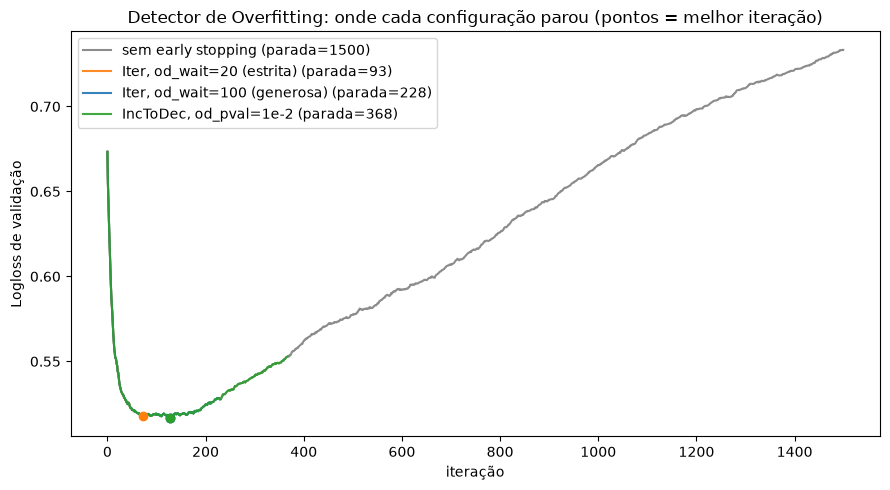

In [4]:
plt.figure(figsize=(9, 5))
colors = {"sem early stopping": "gray", "Iter, od_wait=20 (estrita)": "tab:orange",
          "Iter, od_wait=100 (generosa)": "tab:blue", "IncToDec, od_pval=1e-2": "tab:green"}
for name, m in models.items():
    curve = m.get_evals_result()["validation"]["Logloss"]
    plt.plot(curve, label=f"{name} (parada={len(curve)})", color=colors[name],
             lw=1.5, alpha=0.9)
    plt.scatter([m.get_best_iteration()], [min(curve)], color=colors[name], zorder=5)
plt.xlabel("iteração"); plt.ylabel("Logloss de validação")
plt.title("Detector de Overfitting: onde cada configuração parou (pontos = melhor iteração)")
plt.legend(); plt.tight_layout(); plt.show()

## 3. O que `use_best_model` realmente faz (§4.4.1)

A janela de paciência implica que o treinamento sempre se estende *além* do ponto ótimo. `use_best_model=True` reverte então o modelo para o estado da melhor iteração; com `False`, você preserva a cauda com sobreajuste (overfit). O livro destaca esta etapa como uma verificação "Importante", pois os comportamentos padrão podem variar dependendo da configuração de treinamento.

In [5]:
for ubm in [True, False]:
    m = CatBoostClassifier(iterations=ITERS, depth=6, learning_rate=0.1,
                           random_seed=RANDOM_SEED, verbose=0, allow_writing_files=False)
    m.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=100,
          use_best_model=ubm)
    val_auc = roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])
    print(f"use_best_model={ubm!s:5s} -> árvores mantidas: {m.tree_count_:4d}, "
          f"melhor_iteração: {m.get_best_iteration()}, AUC de validação: {val_auc:.4f}")

use_best_model=True  -> árvores mantidas:  128, melhor_iteração: 127, AUC de validação: 0.8256
use_best_model=False -> árvores mantidas:  228, melhor_iteração: 127, AUC de validação: 0.8253


## 4. Ruído nos rótulos e o ponto de parada selecionado pela validação

Esta varredura avalia se uma quantidade maior de ruído inserido nos rótulos antecipa o ponto de mínimo na validação neste experimento com semente fixa. A direção dessa mudança não é uma regra universal: amostragem, ruído da métrica, regularização e limites finitos de iterações podem alterar o ótimo observado. Reporte resultados com múltiplas execuções e sementes em vez de interpretar o gráfico como uma lei imutável.

In [6]:
rows = []
for noise in [0.0, 0.1, 0.3]:
    Xn, yn = make_classification(n_samples=6_000, n_features=20, n_informative=8,
                                 n_redundant=4, flip_y=noise, random_state=RANDOM_SEED)
    Xn = Xn.astype(np.float32)
    Xn_tr, Xn_va, yn_tr, yn_va = train_test_split(Xn, yn, test_size=0.3,
                                                  random_state=RANDOM_SEED, stratify=yn)
    m = CatBoostClassifier(iterations=ITERS, depth=6, learning_rate=0.1,
                           random_seed=RANDOM_SEED, verbose=0, allow_writing_files=False)
    m.fit(Xn_tr, yn_tr, eval_set=(Xn_va, yn_va), early_stopping_rounds=100, use_best_model=True)
    rows.append({"ruido_rotulo": noise, "melhor_iteracao": m.get_best_iteration(),
                 "parada_apos": len(m.get_evals_result()["validation"]["Logloss"])})
pd.DataFrame(rows)

,ruido_rotulo,melhor_iteracao,parada_apos
0,0.0,532,633
1,0.1,210,311
2,0.3,129,230


## 5. Diagnóstico e resolução de problemas

- Se uma execução for interrompida durante uma trajetória de melhoria, porém ruidosa, teste uma paciência maior, uma métrica de avaliação suave diferente ou uma taxa de aprendizado menor nos dados de desenvolvimento.
- Se atingir o limite máximo de iterações (teto), inspecione se a curva ainda está melhorando, estabilizada ou instável antes de alterar orçamento, capacidade, features ou regularização.

## Principais Aprendizados (Takeaways)

- O early stopping seleciona um prefixo de árvores nos dados de desenvolvimento; isso não prova que as árvores posteriores sejam universalmente prejudiciais.
- `Iter` e `IncToDec` são regras alternativas de detecção. Nenhuma é categoricamente mais agressiva ou superior para um tamanho específico de conjunto de dados.
- Paciência, métrica, taxa de aprendizado e teto de iterações interagem entre si; valide-os sob os limites reais de computação e metas de utilidade/negócio.
- Os efeitos do ruído dos rótulos no ponto de parada são empíricos.
- Congele a escolha do hiperparâmetro antes da avaliação única no conjunto de teste.

## Exercícios

**Exercício 1.** Compare a ausência de detector, `Iter` e `IncToDec` quanto à utilidade na validação e custo sob uma regra pré-declarada. Reporte o candidato selecionado em vez de prescrever um como universalmente ideal.

**Exercício 2.** Faça uma varredura cruzada de taxa de aprendizado e paciência, repetindo com diferentes sementes, e reporte diagnósticos de parada prematura. Trate a escala aproximada de `N` com `1/eta` apenas como uma heurística de orçamento.

**Exercício 3.** Compare métricas de parada e relate as trajetórias obtidas. Métricas baseadas em limiar podem ser descontínuas, mas a AUC é baseada em ordenação (rank) e não é perfeitamente suave em cada atualização finita; escolha com base na estabilidade empírica e na relevância para o ambiente de produção.

### Soluções ocultas

<details><summary>Solução</summary>

**Exercício 1.** Ajuste os candidatos sem detector, com `Iter` e com `IncToDec` nas mesmas divisões de desenvolvimento. Registre a melhor pontuação de validação, árvores retidas, se o teto foi atingido, tempo de treinamento e pontuação em um orçamento fixo comum de árvores quando disponível. Aplique uma regra pré-declarada de custo/utilidade; um detector que para mais cedo não é melhor a menos que seu trade-off qualidade/custo atenda a essa regra.

</details>

<details><summary>Solução</summary>

**Exercício 2.** Cruze taxas de aprendizado com valores de paciência e repita com diferentes sementes do modelo. Sinalize uma parada prematura apenas quando uma continuação mais longa declarada independentemente melhorar a validação acima de uma tolerância. Tabule a taxa de paradas falsas, árvores retidas, melhor pontuação na validação e tempo. Compare as proporções de árvores observadas com a heurística `1/eta` em vez de impô-la rigidamente.

</details>

<details><summary>Solução</summary>

**Exercício 3.** Treine modelos idênticos monitorados por Logloss e AUC, retenha as trajetórias completas de validação de ambos e relate a frequência com que os prefixos selecionados diferem materialmente entre sementes. Avalie os prefixos congelados utilizando a métrica de produção. Escolha a métrica de monitoramento com base em evidências de estabilidade e utilidade, e não em um rótulo abstrato de suavidade.

</details>